In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import os

# Data Exploration

Getting the Twitter dataset.

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/laxmimerit/All-CSV-ML-Data-Files-Download/master/twitter_disaster_tweets.csv", usecols=['text', 'target'])
df.head()

,text,target
0,Our Deeds are the Reason of this #earthquake M...,1
1,Forest fire near La Ronge Sask. Canada,1
2,All residents asked to 'shelter in place' are ...,1
3,"13,000 people receive #wildfires evacuation or...",1
4,Just got sent this photo from Ruby #Alaska as ...,1


Doing some data exploration...

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    7613 non-null   object
 1   target  7613 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 119.1+ KB


In [4]:
df.describe()

,target
count,7613.00000
mean,0.42966
std,0.49506
min,0.00000
25%,0.00000
50%,0.00000
75%,1.00000
max,1.00000


In [5]:
df.isnull().sum()

text      0
target    0
dtype: int64

Shuffle the dataset.

In [8]:
df = df.sample(frac=1).reset_index(drop=True)  # Shuffle the dataset

In [9]:
df

,text,target
0,Texas Seeks Comment on Rules for Changes to Wi...,0
1,Tomorrow is Internet Day. It has been almost 2...,0
2,Accident on I-24 W #NashvilleTraffic. Traffic ...,1
3,Ugh So hungry I'm going to demolish this food!,0
4,@MoFanon ?? your last retweet you would think ...,0
...,...,...
7608,Evacuation order lifted for town of Roosevelt:...,1
7609,If I'm also not mistaken we're sitting right n...,1
7610,Hundreds feared drowned as migrant boat capsiz...,1
7611,Going to the beach with Jim Alves means a guar...,0


In [10]:
df["target"].value_counts()

target
0    4342
1    3271
Name: count, dtype: int64

One token in TinyBert equals ~3 chars -> 160 chars max / 3 chars = 53 => ~60 tokens context window necessary

Matplotlib is building the font cache; this may take a moment.


<Axes: >

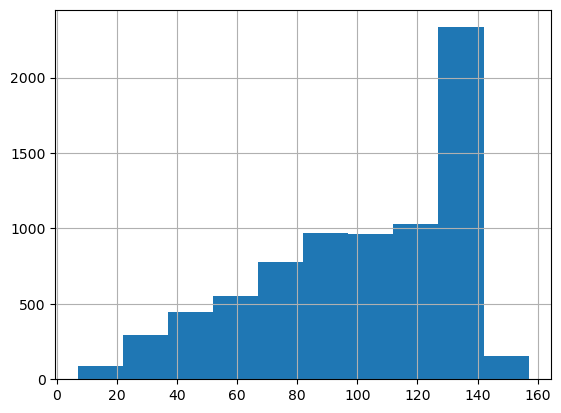

In [11]:
df["text"].str.len().hist()

Rename target to label

In [16]:
df.rename(columns={"target": "label"}, inplace=True)

# Load Data to Dataset

In [17]:
from datasets import Dataset

dataset = Dataset.from_pandas(df)
dataset = dataset.train_test_split(test_size=0.2, shuffle=True, seed=42)

In [18]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 6090
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1523
    })
})

In [19]:
id2label = {0: "general", 1: "disaster"}
label2id = {"general": 0, "disaster": 1}

In [20]:
from transformers import AutoTokenizer
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_ckpt = "huawei-noah/TinyBERT_General_4L_312D"

tokenizer = AutoTokenizer.from_pretrained(model_ckpt, use_fast=True)

The tokenization function, max_length set to 100 because tweets are not that long in the dataset (cf. above)

In [21]:
def tokenize(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=100)

dataset = dataset.map(tokenize, batched=True, batch_size=None)

Map:   0%|          | 0/6090 [00:00<?, ? examples/s]

Map:   0%|          | 0/1523 [00:00<?, ? examples/s]

In [22]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 6090
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1523
    })
})

Accuracy calculation function

In [23]:
import evaluate
import numpy as np

accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy.compute(predictions=predictions, references=labels)

The model gets linear layer for classification results like in sentiment classification.

In [24]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

model = AutoModelForSequenceClassification.from_pretrained(model_ckpt, num_labels=len(label2id), id2label=id2label, label2id=label2id)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at huawei-noah/TinyBERT_General_4L_312D and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [26]:
args = TrainingArguments(
    output_dir="train_dir",
    overwrite_output_dir=True,
    num_train_epochs=5,
    learning_rate=1e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    compute_metrics=compute_metrics,
    tokenizer=tokenizer
)

Performing the training

In [27]:
trainer.train()

  0%|          | 0/955 [00:00<?, ?it/s]

  0%|          | 0/48 [00:00<?, ?it/s]

{'eval_loss': 0.47737738490104675, 'eval_accuracy': 0.7997373604727511, 'eval_runtime': 1.3748, 'eval_samples_per_second': 1107.785, 'eval_steps_per_second': 34.914, 'epoch': 1.0}


  0%|          | 0/48 [00:00<?, ?it/s]

{'eval_loss': 0.4477717876434326, 'eval_accuracy': 0.8128693368351937, 'eval_runtime': 1.2525, 'eval_samples_per_second': 1215.985, 'eval_steps_per_second': 38.324, 'epoch': 2.0}
{'loss': 0.5062, 'grad_norm': 4.40171480178833, 'learning_rate': 4.764397905759163e-06, 'epoch': 2.62}


...

  0%|          | 0/48 [00:00<?, ?it/s]

{'eval_loss': 0.4544442594051361, 'eval_accuracy': 0.7964543663821405, 'eval_runtime': 1.2599, 'eval_samples_per_second': 1208.787, 'eval_steps_per_second': 38.097, 'epoch': 4.0}


  0%|          | 0/48 [00:00<?, ?it/s]

{'eval_loss': 0.43952587246894836, 'eval_accuracy': 0.8108995403808273, 'eval_runtime': 1.266, 'eval_samples_per_second': 1202.988, 'eval_steps_per_second': 37.914, 'epoch': 5.0}
{'train_runtime': 84.7199, 'train_samples_per_second': 359.419, 'train_steps_per_second': 11.272, 'train_loss': 0.46685254161894635, 'epoch': 5.0}


TrainOutput(global_step=955, training_loss=0.46685254161894635, metrics={'train_runtime': 84.7199, 'train_samples_per_second': 359.419, 'train_steps_per_second': 11.272, 'total_flos': 85277819340000.0, 'train_loss': 0.46685254161894635, 'epoch': 5.0})

Performing an eval run

In [28]:
trainer.evaluate()

  0%|          | 0/48 [00:00<?, ?it/s]

{'eval_loss': 0.43952587246894836,
 'eval_accuracy': 0.8108995403808273,
 'eval_runtime': 1.2963,
 'eval_samples_per_second': 1174.839,
 'eval_steps_per_second': 37.027,
 'epoch': 5.0}

Saving the model

In [29]:
trainer.save_model("tinybert-disaster-tweets")

In [30]:
from transformers import pipeline

data = ['There is a fire in the building', 'I am happy today', 'I am sad today', 
          'I am not feeling well','There is a flood in the city, go to higher ground']

classifier = pipeline("text-classification", model="tinybert-disaster-tweets", device=device)
classifier(data)

[{'label': 'disaster', 'score': 0.8384542465209961},
 {'label': 'general', 'score': 0.8860370516777039},
 {'label': 'general', 'score': 0.8710038661956787},
 {'label': 'general', 'score': 0.882093608379364},
 {'label': 'disaster', 'score': 0.8733751177787781}]

In [ ]:
import boto3

s3 = boto3.client('s3', region_name='eu-north-1')

bucket_name = "mlops-mhofmann"

def upload_file_to_s3(file_name, bucket, object_name=None):
    """Upload a file to an S3 bucket"""
    if object_name is None:
        object_name = os.path.basename(file_name)
    
    try:
        s3.upload_file(file_name, bucket, object_name)
        print(f"File {file_name} uploaded to {bucket}/{object_name}.")
    except Exception as e:
        print(f"Error uploading file: {e}")

def upload_directory_to_s3(directory, s3_prefix):
    """Upload a directory to an S3 bucket"""
    for root, dirs, files in os.walk(directory):
        for file in files:
            file_path = os.path.join(root, file)
            relative_path = os.path.relpath(file_path, directory)
            s3_key = os.path.join(s3_prefix, relative_path)
            # print(file_path, relative_path, s3_key)
            upload_file_to_s3(file_path, bucket_name, s3_key)

In [ ]:
upload_directory_to_s3("tinybert-disaster-tweets", "ml-models/tinybert-disaster-tweets")